In [19]:
# Artificial Neural Network

# Installing Theano
# pip3 install --upgrade --no-deps git+git://github.com/Theano/Theano.git

# Installing Tensorflow
# Install Tensorflow from the website: https://www.tensorflow.org/versions/r0.12/get_started/os_setup.html

# Installing Keras
#pip install --upgrade keras

# Part 1 - Data Preprocessing

import pandas as pd

# Importing the dataset
dataset = pd.read_csv('Churn_Modelling.csv')

from sklearn.preprocessing import LabelEncoder, OneHotEncoder
labelencoder_X_1 = LabelEncoder()
dataset.iloc[:, 4] = labelencoder_X_1.fit_transform(dataset.iloc[:, 4])
labelencoder_X_2 = LabelEncoder()
dataset.iloc[:, 5] = labelencoder_X_2.fit_transform(dataset.iloc[:, 5])


y = dataset.iloc[:, 13].values
X = dataset.drop(['RowNumber','CustomerId','Surname','Tenure','HasCrCard','EstimatedSalary','Exited'], axis = 1)

onehotencoder = OneHotEncoder(categorical_features = [1])
X = onehotencoder.fit_transform(X).toarray()
X = X[:, 1:]



C:\Users\MUJ\Anaconda3\lib\site-packages\sklearn\preprocessing\_encoders.py:368: FutureWarning: The handling of integer data will change in version 0.22. Currently, the categories are determined based on the range [0, max(values)], while in the future they will be determined based on the unique values.
If you want the future behaviour and silence this warning, you can specify "categories='auto'".
In case you used a LabelEncoder before this OneHotEncoder to convert the categories to integers, then you can now use the OneHotEncoder directly.
  warnings.warn(msg, FutureWarning)
C:\Users\MUJ\Anaconda3\lib\site-packages\sklearn\preprocessing\_encoders.py:390: DeprecationWarning: The 'categorical_features' keyword is deprecated in version 0.20 and will be removed in 0.22. You can use the ColumnTransformer instead.
  "use the ColumnTransformer instead.", DeprecationWarning)


In [21]:
# Splitting the dataset into the Training set and Test set
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# Part 2 - Now let's make the ANN!

# Importing the Keras libraries and packages
from keras.models import Sequential
from keras.layers import Dense
# Initialising the ANN
classifier = Sequential()

#n 2n 4n 2n n {n/2 ....n/}
n=8
# Adding the input layer and the first hidden layer
classifier.add(Dense(output_dim = 2*n, init = 'uniform', activation = 'relu', input_dim = n))
classifier.add(Dense(output_dim = 4*n, init = 'uniform', activation = 'relu', input_dim = 2*n))
classifier.add(Dense(output_dim = 2*n, init = 'uniform', activation = 'relu', input_dim = 4*n))
classifier.add(Dense(output_dim = n, init = 'uniform', activation = 'relu', input_dim = 2*n))
classifier.add(Dense(output_dim = int(n/2), init = 'uniform', activation = 'relu', input_dim = n))

# Adding the output layer
classifier.add(Dense(output_dim = 1, init = 'uniform', activation = 'sigmoid'))


# Compiling the ANN
classifier.compile(optimizer = 'adam', loss = 'mean_squared_error', metrics = ['accuracy'])

# Fitting the ANN to the Training set
classifier.fit(X_train, y_train, batch_size = 15, nb_epoch = 100)

# Part 3 - Making the predictions and evaluating the model

# Predicting the Test set results
y_pred = classifier.predict(X_test)
y_pred = (y_pred > 0.5)

# Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

C:\Users\MUJ\Anaconda3\lib\site-packages\ipykernel_launcher.py:22: UserWarning: Update your `Dense` call to the Keras 2 API: `Dense(activation="relu", input_dim=8, units=16, kernel_initializer="uniform")`
C:\Users\MUJ\Anaconda3\lib\site-packages\ipykernel_launcher.py:23: UserWarning: Update your `Dense` call to the Keras 2 API: `Dense(activation="relu", input_dim=16, units=32, kernel_initializer="uniform")`
C:\Users\MUJ\Anaconda3\lib\site-packages\ipykernel_launcher.py:24: UserWarning: Update your `Dense` call to the Keras 2 API: `Dense(activation="relu", input_dim=32, units=16, kernel_initializer="uniform")`
C:\Users\MUJ\Anaconda3\lib\site-packages\ipykernel_launcher.py:25: UserWarning: Update your `Dense` call to the Keras 2 API: `Dense(activation="relu", input_dim=16, units=8, kernel_initializer="uniform")`
C:\Users\MUJ\Anaconda3\lib\site-packages\ipykernel_launcher.py:26: UserWarning: Update your `Dense` call to the Keras 2 API: `Dense(activation="relu", input_dim=8, units=4, kerne

Epoch 1/100
8000/8000 [==============================] - 3s 318us/step - loss: 0.1595 - acc: 0.7960
Epoch 2/100
8000/8000 [==============================] - 1s 86us/step - loss: 0.1336 - acc: 0.7960
Epoch 3/100
8000/8000 [==============================] - 1s 87us/step - loss: 0.1314 - acc: 0.8259
Epoch 4/100
8000/8000 [==============================] - 1s 84us/step - loss: 0.1301 - acc: 0.8333
Epoch 5/100
8000/8000 [==============================] - 1s 96us/step - loss: 0.1291 - acc: 0.8355
Epoch 6/100
8000/8000 [==============================] - 1s 94us/step - loss: 0.1283 - acc: 0.8343
Epoch 7/100
8000/8000 [==============================] - 1s 94us/step - loss: 0.1279 - acc: 0.8348
Epoch 8/100
8000/8000 [==============================] - 1s 96us/step - loss: 0.1271 - acc: 0.8349
Epoch 9/100
8000/8000 [==============================] - 1s 78us/step - loss: 0.1269 - acc: 0.8360
Epoch 10/100
8000/8000 [==============================] - 1s 80us/step - loss: 0.1264 - acc: 0.8343
Epoch 11

8000/8000 [==============================] - 1s 93us/step - loss: 0.0999 - acc: 0.8658
Epoch 83/100
8000/8000 [==============================] - 1s 85us/step - loss: 0.1001 - acc: 0.8683
Epoch 84/100
8000/8000 [==============================] - 1s 89us/step - loss: 0.1001 - acc: 0.8651
Epoch 85/100
8000/8000 [==============================] - 1s 91us/step - loss: 0.1001 - acc: 0.8673
Epoch 86/100
8000/8000 [==============================] - 1s 91us/step - loss: 0.1000 - acc: 0.8671
Epoch 87/100
8000/8000 [==============================] - 1s 86us/step - loss: 0.0998 - acc: 0.8666
Epoch 88/100
8000/8000 [==============================] - 1s 82us/step - loss: 0.0996 - acc: 0.8688
Epoch 89/100
8000/8000 [==============================] - 1s 81us/step - loss: 0.0999 - acc: 0.8660
Epoch 90/100
8000/8000 [==============================] - 1s 83us/step - loss: 0.0996 - acc: 0.8661
Epoch 91/100
8000/8000 [==============================] - 1s 100us/step - loss: 0.0996 - acc: 0.8671
Epoch 92/100

Text(0.5, 15.0, 'Predicted label')

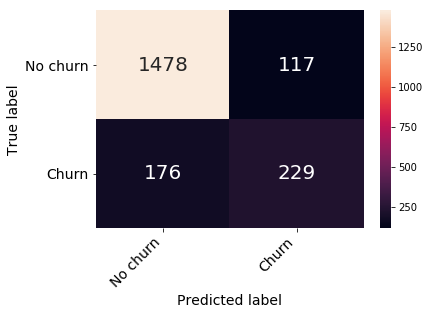

In [22]:
confusion_matrix = confusion_matrix(y_test, y_pred)
confusion_matrix_df = pd.DataFrame(confusion_matrix, ('No churn', 'Churn'), ('No churn', 'Churn'))
heatmap = sns.heatmap(confusion_matrix_df, annot=True, annot_kws={"size": 20}, fmt="d")
heatmap.yaxis.set_ticklabels(heatmap.yaxis.get_ticklabels(), rotation=0, ha='right', fontsize = 14)
heatmap.xaxis.set_ticklabels(heatmap.xaxis.get_ticklabels(), rotation=45, ha='right', fontsize = 14)
plt.ylabel('True label', fontsize = 14)
plt.xlabel('Predicted label', fontsize = 14)

In [23]:
print ("Accuracy : ", accuracy_score(y_test,y_pred)*100) 
      
print("Report : ", classification_report(y_test, y_pred))

Accuracy :  85.35000000000001
Report :                precision    recall  f1-score   support

           0       0.89      0.93      0.91      1595
           1       0.66      0.57      0.61       405

   micro avg       0.85      0.85      0.85      2000
   macro avg       0.78      0.75      0.76      2000
weighted avg       0.85      0.85      0.85      2000

